True distribution P (Sunny, Cloudy, Rainy): [0.5 0.3 0.2]
Entropy H(P): 1.4855 bits

--- Model 1 (Q1): [0.45 0.3  0.25] ---
Cross-Entropy H(P, Q):      1.4971 bits
KL Divergence D_KL(P || Q):  0.0116 bits
H(P) + D_KL(P || Q):         1.4971 bits (diff = 1.28e-13)
Reverse D_KL(Q || P):        0.0121 bits (Asymmetric: True)

--- Model 2 (Q2): [0.2 0.2 0.6] ---
Cross-Entropy H(P, Q):      2.0049 bits
KL Divergence D_KL(P || Q):  0.5195 bits
H(P) + D_KL(P || Q):         2.0049 bits (diff = 1.92e-12)
Reverse D_KL(Q || P):        0.5696 bits (Asymmetric: True)



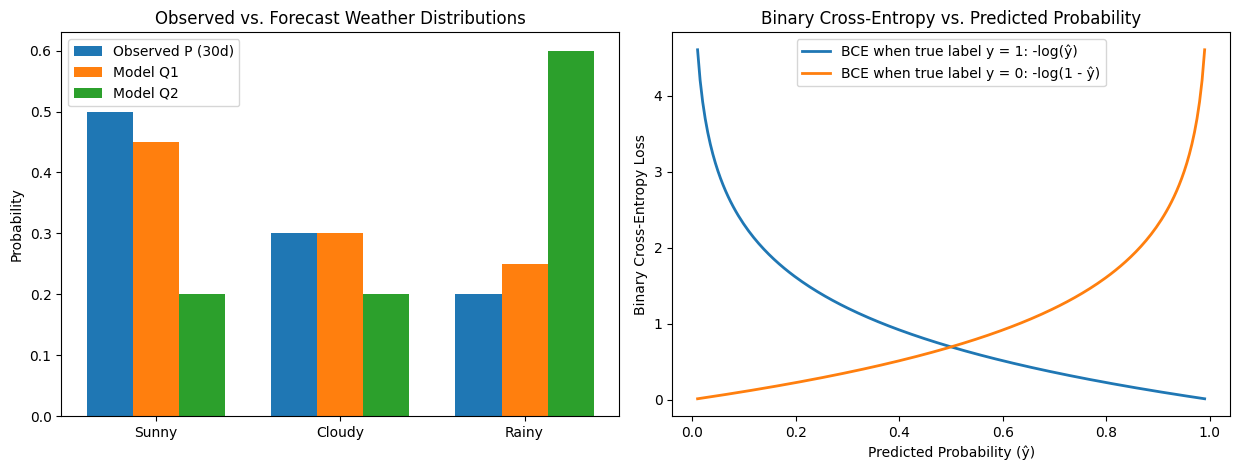

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import rel_entr

# 30 days of observed weather counts -> true distribution P
# States: [Sunny, Cloudy, Rainy]
counts_30d = np.array([15, 9, 6])
P = counts_30d / counts_30d.sum()

# Two competing forecast models Q1 and Q2
Q1 = np.array([0.45, 0.30, 0.25])  # closer to P
Q2 = np.array([0.20, 0.20, 0.60])  # more skewed / further from P

def entropy(p):
    p = np.asarray(p, dtype=float)
    return -np.sum(p * np.log2(p + 1e-12))

def cross_entropy(p, q):
    p, q = np.asarray(p, dtype=float), np.asarray(q, dtype=float)
    return -np.sum(p * np.log2(q + 1e-12))

def kl_div(p, q):
    p, q = np.asarray(p, dtype=float), np.asarray(q, dtype=float)
    return np.sum(rel_entr(p, q)) / np.log(2)  # in bits

H_P = entropy(P)
print(f"True distribution P (Sunny, Cloudy, Rainy): {np.round(P, 3)}")
print(f"Entropy H(P): {H_P:.4f} bits\n")

for name, Q in [("Model 1 (Q1)", Q1), ("Model 2 (Q2)", Q2)]:
    ce_pq = cross_entropy(P, Q)
    kl_pq = kl_div(P, Q)
    kl_qp = kl_div(Q, P)
    print(f"--- {name}: {Q} ---")
    print(f"Cross-Entropy H(P, Q):      {ce_pq:.4f} bits")
    print(f"KL Divergence D_KL(P || Q):  {kl_pq:.4f} bits")
    print(f"H(P) + D_KL(P || Q):         {H_P + kl_pq:.4f} bits (diff = {abs(ce_pq - (H_P + kl_pq)):.2e})")
    print(f"Reverse D_KL(Q || P):        {kl_qp:.4f} bits (Asymmetric: {not np.isclose(kl_pq, kl_qp)})\n")

# Plot comparisons + Binary Cross-Entropy vs predicted probability
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))

# Left: Weather probability distributions
x = np.arange(3)
w = 0.25
axes[0].bar(x - w, P, width=w, label="Observed P (30d)")
axes[0].bar(x, Q1, width=w, label="Model Q1")
axes[0].bar(x + w, Q2, width=w, label="Model Q2")
axes[0].set_xticks(x)
axes[0].set_xticklabels(["Sunny", "Cloudy", "Rainy"])
axes[0].set_ylabel("Probability")
axes[0].set_title("Observed vs. Forecast Weather Distributions")
axes[0].legend()

# Right: Binary Cross-Entropy for y=1 and y=0
p_hat = np.linspace(0.01, 0.99, 200)
bce_y1 = -np.log(p_hat)
bce_y0 = -np.log(1 - p_hat)
axes[1].plot(p_hat, bce_y1, lw=2, label="BCE when true label y = 1: -log(ŷ)")
axes[1].plot(p_hat, bce_y0, lw=2, label="BCE when true label y = 0: -log(1 - ŷ)")
axes[1].set_xlabel("Predicted Probability (ŷ)")
axes[1].set_ylabel("Binary Cross-Entropy Loss")
axes[1].set_title("Binary Cross-Entropy vs. Predicted Probability")
axes[1].legend()

plt.tight_layout()
plt.savefig("exp04_entropy_kl_bce.png", dpi=150, bbox_inches="tight")
plt.show()